In [21]:

from matplotlib import pyplot as plt
import cv2
import numpy as np

In [2]:
rgb = cv2.imread('calib/3d/img_0001.jpg')

In [3]:
rgb.shape

(480, 752, 3)

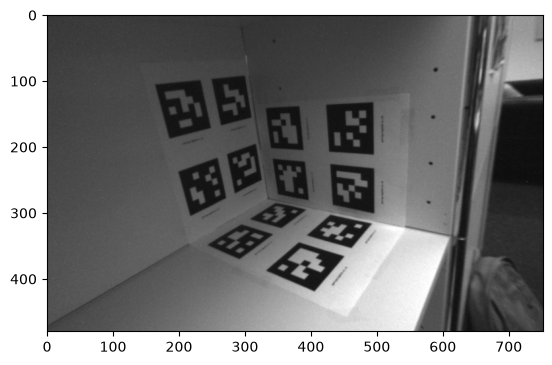

In [4]:
plt.imshow(rgb)

In [5]:
det_corners = np.loadtxt('calib/3d/detected_corners.txt')

In [6]:
det_corners

array([[186.5, 187.5, 264.5, ..., 280.5, 496.5, 300.5],
       [186.5, 186.5, 264.5, ..., 279.5, 496.5, 300.5],
       [187.5, 186.5, 265.5, ..., 279.5, 496.5, 300.5],
       ...,
       [220.5, 216.5, 293.5, ..., 306.5, 547.5, 319.5],
       [214.5, 226.5, 289.5, ..., 313.5, 542.5, 327.5],
       [208.5, 236.5, 283.5, ..., 322.5, 537.5, 336.5]], shape=(210, 24))

In [7]:
X = det_corners[:,0::2]
Y = det_corners[:,1::2]

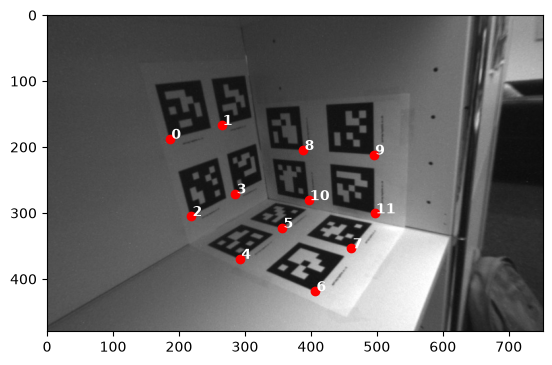

In [8]:
plt.imshow(rgb)
plt.plot(X[0,:], Y[0,:],'ro')
# Etiquetar cada punto con el número de su fila/índice
for i in range(len(X[0, :])):
    # (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
    plt.text(X[0, i] + 2, Y[0, i], str(i), color='white', fontsize=10, weight='bold')

plt.show()



In [9]:
real_corners = np.loadtxt('calib/3d/p_W_corners.txt',delimiter=',')

In [10]:
real_corners


array([[  0.  ,   8.  ,   0.  ],
       [ 10.4 ,   8.  ,   0.  ],
       [  0.  ,  21.5 ,   0.  ],
       [ 10.4 ,  21.5 ,   0.  ],
       [  0.  ,  26.6 , -10.95],
       [ 10.4 ,  26.6 , -10.95],
       [  0.  ,  26.6 , -24.45],
       [ 10.4 ,  26.6 , -24.45],
       [ 19.4 ,  14.6 , -10.95],
       [ 19.4 ,  14.6 , -24.45],
       [ 19.4 ,  25.  , -10.95],
       [ 19.4 ,  25.  , -24.45]])

In [11]:
Xw, Yw, Zw = real_corners[:,0], real_corners[:,1],real_corners[:,2]
Xw

array([ 0. , 10.4,  0. , 10.4,  0. , 10.4,  0. , 10.4, 19.4, 19.4, 19.4,
       19.4])

In [18]:
def obtenerQ3d(imgPts, objPts):
    n = len(objPts)
    uv = np.asarray(imgPts).reshape(n, 2)
    Q = np.zeros((n*2,12))    
    
    for i in range(n):  
        P = np.append(objPts[i], 1)
        u , v = uv[i]
        Q[2*i,0:4] = P
        Q[2*i,8:12] = -u*P
        
        Q[2*i+1,4:8] = P
        Q[2*i+1,8:12] = -v*P
    
    return Q




In [ ]:
k = 0
objPts = np.column_stack((Xw, Yw, Zw))  # (12, 3): puntos 3D
imgPts = np.column_stack((X[k], Y[k]))  # (12, 2): píxeles (u, v) de la imagen k

Q = obtenerQ3d(imgPts, objPts)
print(objPts.shape, imgPts.shape)
print(Q)



In [3]:

#Producto Matricial
def multiplicarMatrices(A,B):
    filasA,columnasA = A.shape
    filasB,columnasB = B.shape
    if columnasA != filasB:
        return None
    M = np.zeros((filasA,columnasB))
    for i in range(filasA):
        for j in range(columnasB):
            suma = 0
            for k in range(filasB):
                suma += A[i][k] * B[k][j]
            M[i][j] = suma
    return M

def calculaLU(A):
    if A is None:
        return None,None,0

    cant_op = 0
    m=A.shape[0]
    n=A.shape[1]
    Ac = A.copy()
    L = np.eye(n)

    if m!=n or A is None:
        return None,None,0
    cant_op = 0
    for i in range(n):
        if Ac[i,i] == 0:
          return None, None, 0
        for j in range(i+1,n):
            cant_op += 1+ 2*(n-i-1)
            pivot = Ac[j,i] / Ac[i,i]
            L[j,i] = pivot
            Ac[j] = Ac[j] - pivot*Ac[i]
    U = Ac

    return L, U, cant_op

def calculaLDV(A):
  n = A.shape[0]
  D = np.eye(n)
  D_inv = np.eye(n)
  L,U,cant = calculaLU(A)
  if L is None:
    return None, None, None
  for i in range(n):
    D[i,i] = U[i,i]
    D_inv[i,i] = 1/U[i,i]

  # Arriba calculo la inversa directamente, Me quede V = D^-1@V
  V = multiplicarMatrices(D_inv, U)
  return L,D,V

def norma(x,p):
    max = 0
    res = 0
    if x.ndim ==1:
      if p == 'inf':
        for i in range(len(x)):
          if max < abs(x[i]):
            max = abs(x[i])
        return max

      for i in range(len(x)):
          res+= abs(x[i])**p
      return res**(1/p)

    n = x.shape[1]
    resultado = np.zeros(n)

    for j in range(n):
      resultado[j] = norma(x[:,j],p)
    return resultado


def calcularAx(A, v):
    w = np.zeros((A.shape[0]))
    for i in range(A.shape[0]):
        row = v * A[i]
        sum_row = 0
        for elem in row:
            sum_row += elem
        w[i] = sum_row
    return w

def f(A, v):
    w = calcularAx(A, v)
    norm = norma(w,2)
    if norm > 0:
        w = w/norm
    return w

def f_k(A, v, k):
    for i in range(k):
        v = f(A, v)
    return v


def prodVect(v,w):
  n = len(v)
  suma = 0
  for i in range(n):
    suma += v[i]*w[i]
  return suma

def metpot2k(A,tol=1e-15,K=1000):
  fil,col = A.shape
  v = np.random.rand(fil)
  v_p = f_k(A,v,2)
  e = v_p.T @ v
  k = 0
  while abs(e - 1) > tol and k < K:
    v = v_p
    v_p = f_k(A,v,2)
    e = prodVect(v_p,v)
    k += 1
  lamb = prodVect(v_p.T, calcularAx(A,v_p))
  eps = e - 1
  return v, lamb, k, eps

def diagRH(A,tol=1e-15,K=1000):
  fil,col = A.shape
  v1, lamb1, _, _ = metpot2k(A,tol,K)
  I = np.eye(fil)
  u = (I[:,0]-v1).reshape(-1, 1)
  H_v1 = I-2*(u@u.T)/(u.T@u)
  if fil == 2:
    S = H_v1
    D = H_v1 @ A @ H_v1.T
    return S,D
  else:
    B = H_v1 @ A @ H_v1.T
    A_2 = B[1:fil,1:fil]
    S_2, D_2 =  diagRH(A_2,tol,K)
    D = np.zeros((fil,fil))
    D[0,0] = lamb1
    D[1:,1:] = D_2
    S = np.eye(fil)
    S[1:,1:] = S_2
    S = H_v1 @ S
    return S, D


def svd_reducida(A,k="max",tol=1e-15):
    fil,col = A.shape
    traspuesta = fil < col
    if traspuesta:
      A = A.T

    diagAtA = A.T @ A
    V, sigma = diagRH(diagAtA,tol)

    V, D = diagRH(A.T @ A, tol)
    autoval = np.diag(D)

    idx = np.argsort(autoval)[::-1]      # de mayor a menor
    autoval, V = autoval[idx], V[:, idx]

    mask = autoval > tol                 # descarta autovalores nulos
    autoval, V = autoval[mask], V[:, mask]

    if k == "max":
        k = len(autoval)                 # todos los no nulos
    k = min(k, len(autoval))             # nunca más que los no nulos

    hatSig = np.sqrt(autoval[:k])
    hatV = V[:, :k]

    B = A @ hatV
    U_hat = B / norma(B,2)

    if traspuesta:
      U_hat ,hatV = hatV, U_hat
    return U_hat, hatSig, hatV


def QR_con_GS(A):
  fil, col = A.shape
  if col != fil:
    return None
  Q = np.zeros((fil,col))
  R = np.zeros((fil,col))
  norm_a1 = norma(A[:,0],2)
  Q[:,0] = A[:,0]/norm_a1
  R[0,0] = norm_a1
  for j in range(1,fil):
    Q[:,j] = A[:,j]
    for k in range(j):
      R[k,j] = Q[:,k].T@Q[:,j]
      Q[:,j] -= R[k,j]*Q[:,k]
    norma_qj = norma(Q[:,j],2)
    Q[:,j] = Q[:,j]/norma_qj
    R[j,j] = norma_qj
  return Q,R

def res_tri(L,b, inferior=True):
  n = L.shape[0]
  x = np.zeros(n)
  bc = b.copy()
  if inferior:
    for i in range(n):
      for j in range(i):
        bc[i] -= L[i,j]*x[j]
      x[i] = bc[i] / L[i,i]
  else:
      for i in range(n-1, -1, -1):
        for j in range(i+1,n):
          bc[i] -= x[j]*L[i,j]
        x[i] = bc[i] / L[i,i]

  return x


def inversa(A):
  n = A.shape[0]
  I = np.eye(n)
  L,U,cant = calculaLU(A)
  if L is None:
    return None
  A_inv = np.zeros((n,n))
  for i in range(n):
    e_i = I[:,i]
    y = res_tri(L,e_i,True)
    x = res_tri(U,y,False)
    A_inv[:,i] = x
  return A_inv




In [2]:
def calculaCholesky(A):
    L,D,L = calculaLDV(A)
    D_raiz = np.diag(np.sqrt(np.diag(D)))
    return multiplicarMatrices(L,D_raiz)

In [ ]:
def resolverDLT3D(Q):
    U, sigma, V = svd_reducida(Q)
    m = V[-1] #ultima fila, seria la ultima columna de V
    return m.reshape(3,4)

In [ ]:
def devolverMatricesCalibracion3d(M):
    J = np.array([
    [0, 0, 1],
    [0, 1, 0],
    [1, 0, 0]
    ])

    A = M[:,:3].copy()
    b = M[:,3].copy()
    B = multiplicarMatrices(J,multiplicarMatrices(A.T,J))

    Q, R = QR_con_GS(B)

    K = multiplicarMatrices(J,multiplicarMatrices(R.T,J))
    R_hat = multiplicarMatrices(J,multiplicarMatrices(Q.T,J))

     # Ajustar signos de la diagonal de K
    D = np.diag(np.sign(np.diag(K)))

    K = multiplicarMatrices(K, D) # para que quede positiva
    R_hat = multiplicarMatrices(D, R_hat) # lo mismo

    # Normalizar K[2,2] = 1
    escala = K[2, 2]
    K = K / escala
    b = b / escala
    
    t = res_tri(K,b)

    return R_hat, t, K

In [ ]:
def devolverMatricesCalibracion3d(m, misma_focal=False, sin_skew=False):
    J = np.array([
    [0, 0, 1],
    [0, 1, 0],
    [1, 0, 0]
    ])

    A = M[:,:3].copy()
    b = M[:,3].copy()
    B = multiplicarMatrices(J,multiplicarMatrices(A.T,J))

    Q, R = QR_con_GS(B)

    K = multiplicarMatrices(J,multiplicarMatrices(R.T,J))
    R_hat = multiplicarMatrices(J,multiplicarMatrices(Q.T,J))

     # Ajustar signos de la diagonal de K
    D = np.diag(np.sign(np.diag(K)))

    K = multiplicarMatrices(K, D) # para que quede positiva
    R_hat = multiplicarMatrices(D, R_hat) # lo mismo

    # Normalizar K[2,2] = 1
    escala = K[2, 2]
    K = K / escala
    b = b / escala
    
    t = res_tri(K,b)
    if misma_focal:
        f = (K[0,0]+K[1,1])/2 # tomo la media para no alejarme de sus valores originales
        K[0,0] , K[1,1] = f
    if sin_skew:
        K[0,1] = 0
    

    return R_hat, t, K    

In [ ]:
#copy paste casi igual de la 3D
def obtenerQ2d(imgPts, objPts): 
    n = len(objPts)
    uv = np.asarray(imgPts).reshape(n, 2)
    Q = np.zeros((n*2,9))    
    
    for i in range(n):  
        P = np.append(objPts[i], 1)
        u , v = uv[i]
        Q[2*i,0:3] = P
        Q[2*i,6:9] = -u*P
        
        Q[2*i+1,3:6] = P
        Q[2*i+1,6:9] = -v*P
    
    return Q

In [ ]:
def calcularV(H,i,j):
    v = np.array([
           H[0,i]*H[0,j],
           H[0,i]*H[1,j]+H[1,i]*H[0,j],
           H[2,i]*H[0,j]+H[0,i]*H[2,j],
           H[1,i]*H[1,j],
           H[2,i]*H[1,j]+H[1,i]*H[2,j],
           H[2,i]*H[2,j]
        ])
    return v

def armarA(Hlst):
    
    n = len(Hlst)
    A = np.zeros((2*n,6))
    j = 0
    for H in Hlst:
        v12 = calcularV(H,0,1)
        v11 = calcularV(H,0,0)
        v22 = calcularV(H,1,1)
        V = np.array([v12,v11-v22])
        
        A[2*j : 2*j+2,:] = V
        j = j + 1
    
    return A

In [ ]:
def calcularMatrizK2D(A):
    U, S, V = svd_reducida(A)
    b = V.T[-1] # la transpongo para quedarme con la ultima columna de V
                 # el cual me da el valor singular minimo
    B = np.array([
                [b[0],b[1],b[3]],
                [b[1],b[2],b[4]],
                [b[3],b[4],b[5]]
                ])
    L = calculaCholesky(B)
    K = inversa(L.T)
    K = K / K[2,2] # normalizo la matriz por K[3,3]
    return K
    